# Bessel zeros, grid scale ratios, and radial similarity

Reproduces Fig. 6 (Sec. 2.4, Appendix G), and demonstrates the claim it is the last step
of.

Rewriting the similarity function in polar coordinates and applying the Jacobi–Anger
expansion splits it into a radial part and angular terms:

$$C(r,\theta) = \sum_j \alpha_{0,j}^2 J_0(k_j r)
  + 2\sum_{n=1}^{\infty}(-1)^n \mathrm{Re}\Big[e^{2in\theta}\sum_j \alpha_{0,j}^2 J_{2n}(k_j r)e^{-2in\phi_j}\Big]$$

Two things follow, and both are checked below.

**The angular terms can be switched off.** The inner phasor sum vanishes unless the
harmonic order is a multiple of the symmetry order $M$, and — if the module orientations
themselves form a root-of-unity set of size $L$ — also a multiple of $L$. When $M$ and $L$
are **coprime**, the lowest surviving angular term is $\cos(2ML\theta)$, and since
$J_\gamma(z)\approx (z/2)^\gamma/\Gamma(\gamma+1)$ for small $z$, high-order terms are
negligible over a wide range of $r$. The similarity is then effectively radial,
$C(r) \approx ML\sum_k \alpha_{0,k}^2 J_0(k_k r)$ — a Fourier–Bessel series.

**The ring radii predict grid module spacing.** A Fourier–Bessel series wants its radii at
the zeros of $J_0$. The ratio of successive zeros starts above 2 and decays toward 1, so
its running average passes $\sqrt{2}$ at low truncation — inside the experimentally
observed spread of grid module spacing ratios. The paper's point is that the familiar
$\sqrt{2}$ need not be assumed to maximise spatial range; it can fall out of approximating
a radial kernel.

Nothing here is fitted. `bessel_module_frequencies` and `multiscale_wavevectors` build the
spectrum; `tests/test_generators.py` checks it against the closed form above.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.special import j0

from expmap.generators import (
    bessel_module_frequencies,
    block_diag_skew,
    build_generators,
    multiscale_wavevectors,
)
from expmap.linalg import random_orthogonal_matrix, starting_state
from expmap.model import ExponentialMap

# Figure parameters. NUM_ZEROS = 15 matches Fig. 6; K = 5 modules with M = 3 hexagonal
# orientations is the smallest setting that shows the radial behaviour clearly.
NUM_ZEROS = 15
K = 5
M = 3
ARENA_SIZE = 6.0
SEED = 0

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

first ratios: [2.295 1.568 1.363 1.266]
cumulative average crosses sqrt(2) = 1.4142 at truncation 8
  value there: 1.3941  (1.4% away)


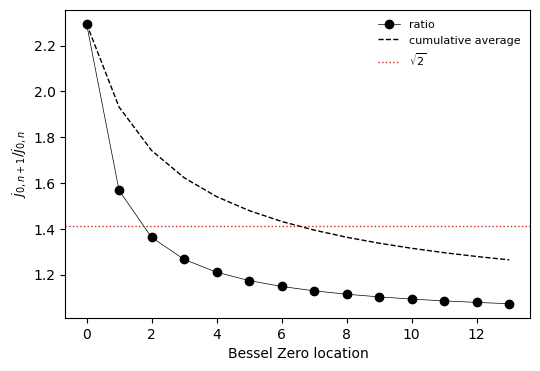

In [2]:
# Fig. 6. The absolute scale cancels in a ratio, so this is a property of the J0 zeros
# alone -- arena_size only sets where the series sits, not the spacing.
frequencies = bessel_module_frequencies(NUM_ZEROS, arena_size=ARENA_SIZE)
ratios = frequencies[1:] / frequencies[:-1]
cumulative = np.cumsum(ratios) / np.arange(1, len(ratios) + 1)

plt.figure(figsize=(6, 4))
plt.plot(ratios, "ko-", linewidth=0.5, label="ratio")
plt.plot(cumulative, "k--", linewidth=1, label="cumulative average")
plt.axhline(np.sqrt(2), color="C3", linewidth=1, linestyle=":", label=r"$\sqrt{2}$")
plt.xlabel("Bessel Zero location")
plt.ylabel(r"$j_{0,n+1} / j_{0,n}$")
plt.legend(fontsize=8, frameon=False)
plt.savefig(FIGURE_DIR / "bessel_zeros.pdf", dpi=300, bbox_inches="tight", transparent=True)
plt.savefig(FIGURE_DIR / "bessel_zeros.png", dpi=300, bbox_inches="tight", transparent=True)

crossing = int(np.argmax(cumulative < np.sqrt(2)))
print(f"first ratios: {np.round(ratios[:4], 3)}")
print(f"cumulative average crosses sqrt(2) = {np.sqrt(2):.4f} at truncation {crossing + 1}")
print(f"  value there: {cumulative[crossing]:.4f}  ({abs(cumulative[crossing] - np.sqrt(2)) / np.sqrt(2):.1%} away)")

In [3]:
def bessel_model(n_offsets, seed=SEED):
    """K Bessel-spaced rings, M orientations each, in n_offsets rotated sets."""
    k = bessel_module_frequencies(K, arena_size=ARENA_SIZE)
    lambda_x, lambda_y = multiscale_wavevectors(k, M=M, n_offsets=n_offsets)
    N = 2 * len(lambda_x)

    R = random_orthogonal_matrix(N, seed=seed)
    p0 = starting_state(R)
    Gx, Gy = build_generators(block_diag_skew(lambda_x), block_diag_skew(lambda_y), R)
    return ExponentialMap(Gx, Gy), p0, N, k


def similarity_at(model, p0, positions):
    """Similarity of each position to the origin."""
    with torch.no_grad():
        origin = model(torch.zeros(1, 2), p0)[0]
        return (model(positions, p0) @ origin).numpy()


for n_offsets in (1, 2):
    _, _, N, k = bessel_model(n_offsets)
    lowest_harmonic = 2 * M * n_offsets
    coprime = np.gcd(M, n_offsets) == 1
    print(f"L={n_offsets}: N={N:3d}  coprime with M={M}: {coprime}  lowest angular term cos({lowest_harmonic}θ)")
print(f"\nring radii k: {np.round(k, 3)}")

L=1: N= 30  coprime with M=3: True  lowest angular term cos(6θ)
L=2: N= 60  coprime with M=3: True  lowest angular term cos(12θ)

ring radii k: [0.605 1.388 2.176 2.965 3.754]


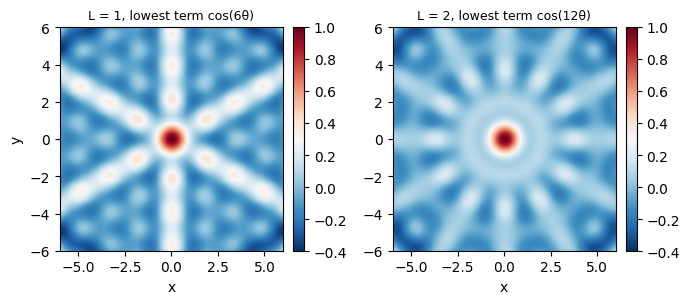

In [4]:
# The similarity maps. With one orientation set the lowest angular term is cos(6θ) and the
# hexagonal structure is visible; adding a second, coprime set pushes it to cos(12θ) and
# what is left is radial.
extent = (-ARENA_SIZE, ARENA_SIZE, -ARENA_SIZE, ARENA_SIZE)
grid = np.linspace(-ARENA_SIZE, ARENA_SIZE, 201)
X, Y = np.meshgrid(grid, grid, indexing="ij")
positions = torch.tensor(np.stack([X.ravel(), Y.ravel()], axis=1), dtype=torch.float32)

fig, axs = plt.subplots(1, 2, figsize=(7, 3.2))
maps = {}
for ax, n_offsets in zip(axs, (1, 2)):
    model, p0, _, _ = bessel_model(n_offsets)
    maps[n_offsets] = similarity_at(model, p0, positions).reshape(X.shape)
    im = ax.imshow(maps[n_offsets].T, extent=extent, origin="lower", cmap="RdBu_r", vmin=-0.4, vmax=1.0)
    ax.set_title(f"L = {n_offsets}, lowest term cos({2 * M * n_offsets}θ)", fontsize=9)
    ax.set_xlabel("x")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
axs[0].set_ylabel("y")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "bessel_similarity_maps.svg", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "bessel_similarity_maps.png", dpi=300, bbox_inches="tight")

peak-to-peak angular variation:
  L=1: r=0.5: 8.68e-04  r=1.0: 3.91e-02  r=2.0: 5.37e-01  r=3.0: 3.14e-01
  L=2: r=0.5: 8.94e-07  r=1.0: 3.50e-06  r=2.0: 4.62e-03  r=3.0: 1.33e-01


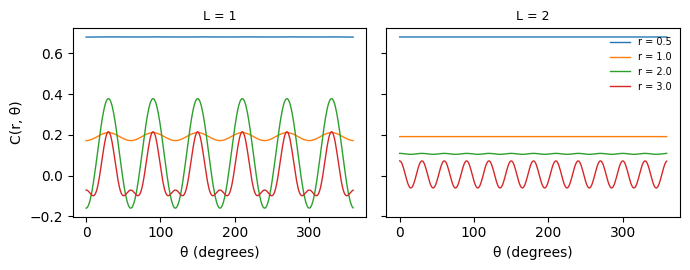

In [5]:
# Sweep the angle at fixed radius: how much does C(r, θ) actually vary with direction?
theta = np.linspace(0, 2 * np.pi, 360, endpoint=False)
radii = [0.5, 1.0, 2.0, 3.0]

fig, axs = plt.subplots(1, 2, figsize=(7, 2.8), sharey=True)
for ax, n_offsets in zip(axs, (1, 2)):
    model, p0, _, _ = bessel_model(n_offsets)
    for r in radii:
        ring = torch.tensor(np.stack([r * np.cos(theta), r * np.sin(theta)], axis=1), dtype=torch.float32)
        ax.plot(np.degrees(theta), similarity_at(model, p0, ring), linewidth=1, label=f"r = {r}")
    ax.set_title(f"L = {n_offsets}", fontsize=9)
    ax.set_xlabel("θ (degrees)")
axs[0].set_ylabel("C(r, θ)")
axs[1].legend(fontsize=7, frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "bessel_angular_profiles.svg", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "bessel_angular_profiles.png", dpi=300, bbox_inches="tight")

print("peak-to-peak angular variation:")
for n_offsets in (1, 2):
    model, p0, _, _ = bessel_model(n_offsets)
    spreads = []
    for r in radii:
        ring = torch.tensor(np.stack([r * np.cos(theta), r * np.sin(theta)], axis=1), dtype=torch.float32)
        C = similarity_at(model, p0, ring)
        spreads.append(C.max() - C.min())
    print(f"  L={n_offsets}: " + "  ".join(f"r={r}: {s:.2e}" for r, s in zip(radii, spreads)))

max |empirical - Fourier-Bessel series| = 1.52e-07


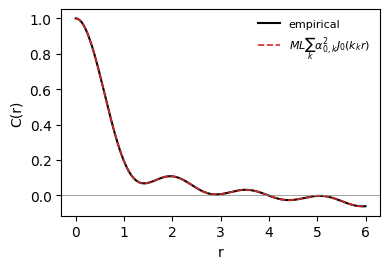

In [6]:
# With the angular terms suppressed, what remains should be exactly the Fourier-Bessel
# radial series C(r) = M L sum_k alpha_0,k^2 J0(k_k r), with uniform alpha_0,k^2 = 1/N.
L = 2
model, p0, N, k = bessel_model(L)

r = np.linspace(0, ARENA_SIZE, 200)
empirical = np.array(
    [
        similarity_at(
            model,
            p0,
            torch.tensor(
                np.stack([ri * np.cos(theta), ri * np.sin(theta)], axis=1),
                dtype=torch.float32,
            ),
        ).mean()
        for ri in r
    ]
)
series = np.array([np.sum((2 / N) * M * L * j0(k * ri)) for ri in r])

print(f"max |empirical - Fourier-Bessel series| = {np.abs(empirical - series).max():.2e}")

plt.figure(figsize=(4, 2.8))
plt.plot(r, empirical, "k", linewidth=1.5, label="empirical")
plt.plot(r, series, "C3--", linewidth=1.2, label=r"$ML\sum_k \alpha_{0,k}^2 J_0(k_k r)$")
plt.axhline(0, color="gray", linewidth=0.5)
plt.xlabel("r")
plt.ylabel("C(r)")
plt.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "bessel_radial_series.svg", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "bessel_radial_series.png", dpi=300, bbox_inches="tight")